In [1]:
import numpy as np
import matplotlib.pyplot as plt

Analytical:
$$\frac{dp}{dz} = -\frac{gp}{R_dT}$$
$$\frac{dp}{dz} = -\frac{gp}{R_d(T_{sfc}+\gamma z)}$$
$$p(z) = p_0 \left(1 + \frac{\gamma z}{T_{sfc}}\right)^{-\frac{g}{R_d\gamma}}$$

Discrete:
$$p_{i+1} = p_i - \frac{gp_i}{R_dT_{\frac{1}{2}}}\Delta z$$

In [2]:
def p_numerical(z,g = 9.81, Rd = 287.05, Tsfc = 293, gamma = -0.006, p0 = 101800):
    """
    """
    dz = z[1] - z[0]
    p = np.zeros(len(z))
    p[0] = p0 #pa

    for i in range(len(p)-1):
        T_lower = Tsfc + gamma * z[i]
        T_upper = Tsfc + gamma * z[i+1] 
        T_12 = (T_lower + T_upper) / 2 
        p_new = p[i] - (g * p[i] * dz) / (Rd * T_12)

        p[i+1] = p_new

    return p

def p_analytical(z, g = 9.81, Rd = 287.05, Tsfc = 293, gamma = -0.006, p0 = 101800):

    T = Tsfc + gamma * z

    p = p0 * (T / Tsfc) ** ((-g) / (Rd * gamma))

    return p

<>:8: SyntaxWarning: invalid escape sequence '\D'
<>:8: SyntaxWarning: invalid escape sequence '\D'
C:\Users\kubag\AppData\Local\Temp\ipykernel_31392\3406415020.py:8: SyntaxWarning: invalid escape sequence '\D'
  plt.plot(p_num / 1000,z/1000, label = f'Numerical ($\Delta x = {int(z[1]-z[0])}$)')


<function matplotlib.pyplot.show(close=None, block=None)>

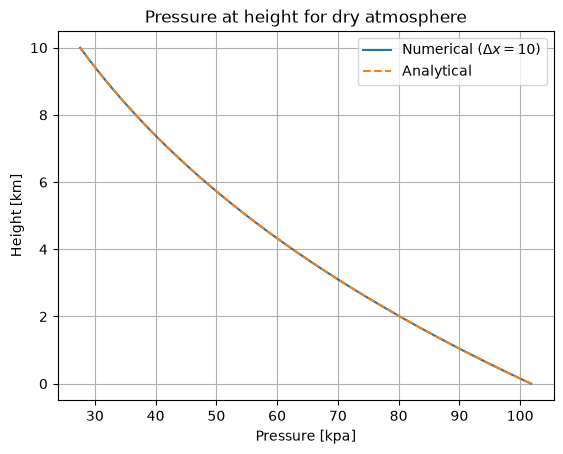

In [8]:
n = 1000
z = np.linspace(0,10000,n+1)
p_num = p_numerical(z)

p_an = p_analytical(z)


plt.plot(p_num / 1000,z/1000, label = f'Numerical ($\Delta x = {int(z[1]-z[0])}$)')
plt.plot(p_an / 1000, z / 1000, label = 'Analytical', linestyle = 'dashed')
plt.ylabel('Height [km]')
plt.xlabel('Pressure [kpa]')
plt.title('Pressure at height for dry atmosphere')

plt.legend()
plt.grid()
plt.show

In [13]:
def density(p,z, Rd = 287.05, Tsfc = 293, gamma = -0.006):

    rho = np.zeros(len(p))

    for i in range(len(z)):
        rho[i] = p[i] / (Rd * (Tsfc + gamma * z[i]))

    return rho

surface density: 1.21km/m3
Density is half of surface at height 6.7km


<function matplotlib.pyplot.show(close=None, block=None)>

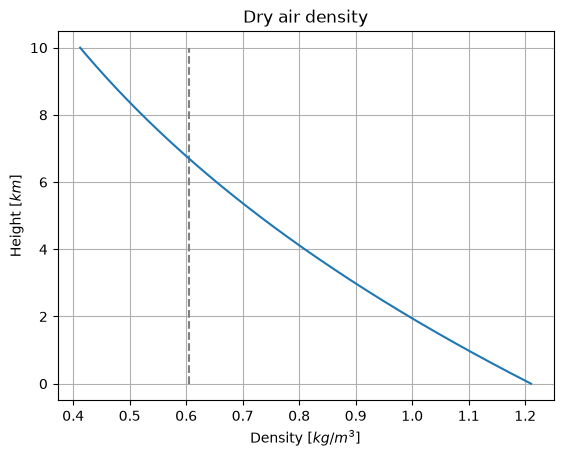

In [39]:
rho = density(p_num,z)

rho_sfc = rho[0]
print(f"surface density: {rho_sfc:.2f}km/m3")

i = 0
while i < len(rho) and rho[i] >= (rho_sfc / 2):
    i += 1
half_rho_z = z[i] if i < len(rho) else None

print(f'Density is half of surface at height {half_rho_z / 1000}km')

plt.plot((rho_sfc / 2) * np.ones(len(rho)), z / 1000, color = 'gray', linestyle = 'dashed')

plt.plot(rho, z / 1000)

plt.xlabel('Density [$kg/m^3$]')
plt.ylabel('Height [$km$]')
plt.title('Dry air density')
plt.grid()
plt.show

In [32]:
def vapor_q(z, p, RH, Tsfc = 293, gamma = -0.006, Rd = 287.05, Rv = 461.50):

    T = Tsfc + gamma * z

    e_sat = 610.78 * np.exp((17.2694 * (T - 273.16)) /  (T - 35.86))

    e_vap = RH * e_sat

    q_vap = e_vap / (((Rv / Rd) * (p - e_vap)) + e_vap)

    q_vap = q_vap * 1000 # convert to g/kg

    return q_vap

For Tsfc = 271, q_vap at 5km is 0.369 g/kg
For Tsfc = 303, q_vap at 5km is 5.480 g/kg


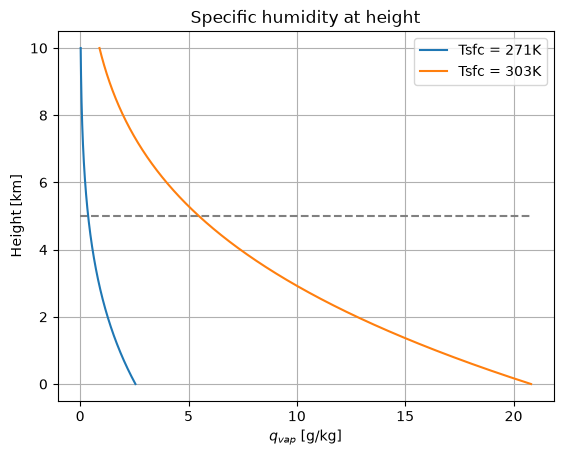

In [33]:
q_vap1 = vapor_q(z, p_num, 0.8, Tsfc = 271)
q_vap2 = vapor_q(z, p_num, 0.8, Tsfc = 303)

plt.plot(np.linspace(0, max(q_vap2), len(q_vap2)), 5 * np.ones(len(q_vap1)), color = 'gray', linestyle = 'dashed')

plt.plot(q_vap1, z / 1000, label = 'Tsfc = 271K')
plt.plot(q_vap2, z / 1000, label = 'Tsfc = 303K')

print(f'For Tsfc = 271, q_vap at 5km is {q_vap1[int(len(z) / 2)]:.3f} g/kg')
print(f'For Tsfc = 303, q_vap at 5km is {q_vap2[int(len(z) / 2)]:.3f} g/kg')

plt.xlabel('$q_{vap}$ [g/kg]')
plt.ylabel('Height [km]')
plt.title('Specific humidity at height')
plt.legend()
plt.grid()
plt.show()